# 06 Market moods: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded or computed here** (the file is filtered while reading; checkpoints without a full next-month outcome are dropped and counted).

**This measures labels, not a trading strategy. No trading costs are applied.** An average excess under about 0.2% a month would likely not survive the 0.10%-per-trade cost in practice.

Rules (all use only information available at the checkpoint close):
- **Trend:** SPY adjusted close on the checkpoint vs its 200-trading-day simple average (including that day). At or above = **uptrend**; below = **downtrend**.
- **Storminess:** SPY's 21-day volatility (standard deviation of the last 21 daily returns) vs the median of that same 21-day volatility over the previous 252 trading days (the 252 days before the checkpoint, not including it). Above the median = **stormy**; otherwise **calm**.
- **Mood** = trend x storminess: calm uptrend, stormy uptrend, calm downtrend, stormy downtrend.
- **Checkpoints:** the same 21-day grid as notebooks 02-05 (every 21st trading day counted from 1999-01-04), starting at the first one with enough history (200 days for the trend; 21 + 252 for storminess).
- **Outcomes:** from the NEXT day's close to 21 trading days after that (same one-day delay as notebooks 03 and 04). Sector average = simple mean of the sector funds' changes over that span (funds that have prices at both ends). **Defensive excess** = mean of the XLP, XLU, XLV changes minus the sector average.
- **Rough 95% ranges:** resample checkpoint dates with replacement (2,000 draws, fixed seed).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from rotation.data import load_prices, wide
from rotation.returns import daily_returns
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)
N = 21; DELAY = 1; SPAN = DELAY + N
SECT = config.SECTORS; DEF = ["XLP", "XLU", "XLV"]
MOODS = ["calm uptrend", "stormy uptrend", "calm downtrend", "stormy downtrend"]
B = 2000

## 1. Load build years only (SPY, TLT, 11 sector funds; adjusted close)

In [2]:
df = load_prices(symbols=["SPY", "TLT"] + SECT, fields=["adj_close"], end=config.BUILD_END)
assert df.date.max() <= pd.Timestamp(config.BUILD_END)
P = wide(df, "adj_close")[["SPY", "TLT"] + SECT]
n = len(P)
assert n == 5536                      # same trading calendar as notebooks 02-05
print(P.index.min().date(), "to", P.index.max().date(), "|", n, "days")

1999-01-04 to 2020-12-31 | 5536 days


## 2. Mood at each checkpoint, and next-month outcomes

In [3]:
spy = P["SPY"]
ret = daily_returns(P)                                   # daily returns (pct change of adjusted close)
sma200 = spy.rolling(200).mean()                         # 200 closes ending on the day
vol21 = ret["SPY"].rolling(21).std()                     # std of the last 21 daily returns ending on the day
med252 = vol21.shift(1).rolling(252).median()            # median of that vol over the previous 252 days (excludes today)
uptrend = spy >= sma200
stormy = vol21 > med252

S = P[SECT]
sec_avg_out = (S.shift(-SPAN) / S.shift(-DELAY) - 1).mean(axis=1, skipna=True)
fund_out = S.shift(-SPAN) / S.shift(-DELAY) - 1
fund_excess = fund_out.sub(sec_avg_out, axis=0)
def_out = fund_out[DEF].mean(axis=1)
def_excess = def_out - sec_avg_out
spy_out = spy.shift(-SPAN) / spy.shift(-DELAY) - 1

valid = sma200.notna() & med252.notna()
checks = [i for i in range(N, n, N) if valid.iloc[i]]
print("first checkpoint:", P.index[checks[0]].date(), "(position", checks[0], ") | last:", P.index[checks[-1]].date(), "| checkpoints:", len(checks))

rows = []
for i in checks:
    has_out = i + SPAN <= n - 1
    r = dict(pos=i, date=P.index[i], year=P.index[i].year, trend="uptrend" if uptrend.iloc[i] else "downtrend",
             storm="stormy" if stormy.iloc[i] else "calm", has_outcome=has_out,
             spy_ret=spy_out.iloc[i] if has_out else np.nan,
             spy_vol_ann=ret["SPY"].iloc[i + DELAY + 1: i + SPAN + 1].std() * np.sqrt(252) if has_out else np.nan,
             def_excess=def_excess.iloc[i] if has_out else np.nan)
    for s in SECT:
        r["x_" + s] = fund_excess.iloc[i][s] if has_out else np.nan
    rows.append(r)
obs = pd.DataFrame(rows)
obs["mood"] = obs.storm + " " + obs.trend
dropped = obs[~obs.has_outcome].date.dt.date.astype(str).tolist()
print("checkpoints without a full next-month outcome inside the build years (dropped from outcome results):", dropped)

# independent hand check of one checkpoint with plain numpy
i0 = checks[60]
c = spy.values
sma_h = c[i0 - 199:i0 + 1].mean()
rr = c[1:] / c[:-1] - 1                                   # rr[k] = return on day k+1
v_h = lambda j: rr[j - 21:j].std(ddof=1)                  # std of returns on days j-20..j
med_h = np.median([v_h(j) for j in range(i0 - 252, i0)])
r0 = obs[obs.pos == i0].iloc[0]
assert (r0.trend == "uptrend") == (c[i0] >= sma_h) and (r0.storm == "stormy") == (v_h(i0) > med_h)
hand_out = c[i0 + SPAN] / c[i0 + DELAY] - 1
assert abs(r0.spy_ret - hand_out) < 1e-12
sa = np.mean([P[s].values[i0 + SPAN] / P[s].values[i0 + DELAY] - 1 for s in SECT if not np.isnan(P[s].values[i0 + DELAY]) and not np.isnan(P[s].values[i0 + SPAN])])
hd = np.mean([P[s].values[i0 + SPAN] / P[s].values[i0 + DELAY] - 1 for s in DEF]) - sa
assert abs(r0.def_excess - hd) < 1e-12
print("hand check passed for", P.index[i0].date(), "->", r0.mood)
obs.to_csv(R / "06_observations.csv", index=False)

first checkpoint: 2000-02-02 (position 273 ) | last: 2020-12-14 | checkpoints: 251
checkpoints without a full next-month outcome inside the build years (dropped from outcome results): ['2020-12-14']
hand check passed for 2005-02-08 -> calm uptrend


## 3. Result 1: mood counts and shares
All labeled checkpoints (no outcome needed).

In [4]:
cnt = obs.mood.value_counts().reindex(MOODS).fillna(0).astype(int)
t_counts = pd.DataFrame({"checkpoints": cnt, "share_pct": cnt / cnt.sum() * 100})
t_counts.loc["All"] = [cnt.sum(), 100.0]
t_counts.round(1).to_csv(R / "06_mood_counts.csv")
print(t_counts.round(1).to_string())
print()
for k, g in [("trend", "trend"), ("storminess", "storm")]:
    print(k, obs[g].value_counts().to_dict())

                  checkpoints  share_pct
mood                                    
calm uptrend            112.0       44.6
stormy uptrend           72.0       28.7
calm downtrend           16.0        6.4
stormy downtrend         51.0       20.3
All                     251.0      100.0

trend {'uptrend': 184, 'downtrend': 67}
storminess {'calm': 128, 'stormy': 123}


## 4. Result 2: stickiness (D1)
Mood at a checkpoint vs the mood at the next checkpoint (21 trading days later), over all pairs of consecutive labeled checkpoints. Chance level = sum of squared shares (what you would see if the next mood were drawn at random from the overall mood shares). Same for trend alone and storminess alone.

In [5]:
o = obs.sort_values("pos").reset_index(drop=True)
nxt = o.shift(-1)
ok = (nxt.pos - o.pos) == N
pairs = pd.DataFrame({"from_mood": o.mood[ok], "to_mood": nxt.mood[ok], "from_trend": o.trend[ok], "to_trend": nxt.trend[ok],
                      "from_storm": o.storm[ok], "to_storm": nxt.storm[ok]})
tab = pd.crosstab(pairs.from_mood, pairs.to_mood).reindex(index=MOODS, columns=MOODS).fillna(0).astype(int)
tab.index.name = "from \\ to"
tab.to_csv(R / "06_mood_moves_table.csv")
print("consecutive labeled pairs:", len(pairs)); print(tab.to_string())
print("\nshare of each from-mood row that goes to each mood (%):"); print((tab.div(tab.sum(axis=1), axis=0) * 100).round(1).to_string())

def stick(col_from, col_to, labels_all):
    same = (pairs[col_from] == pairs[col_to]).mean() * 100
    sh = labels_all.value_counts(normalize=True)
    return same, (sh ** 2).sum() * 100
rows_s = []
for name, a, b, lab in [("mood (4 values)", "from_mood", "to_mood", obs.mood), ("trend alone", "from_trend", "to_trend", obs.trend),
                        ("storminess alone", "from_storm", "to_storm", obs.storm)]:
    same, chance = stick(a, b, lab)
    rows_s.append(dict(what=name, pairs=len(pairs), stayed_same_pct=same, chance_pct=chance, above_chance_pts=same - chance))
stk = pd.DataFrame(rows_s)
stk.round(2).to_csv(R / "06_stickiness.csv", index=False)
print(); print(stk.round(2).to_string(index=False))
d1_share = stk.stayed_same_pct.iloc[0]
print("\nD1: mood matches the next checkpoint's mood %.1f%% of the time (needs >= 60%%); chance %.1f%%" % (d1_share, stk.chance_pct.iloc[0]))

consecutive labeled pairs: 250
to_mood           calm uptrend  stormy uptrend  calm downtrend  stormy downtrend
from \ to                                                                       
calm uptrend                71              32               1                 7
stormy uptrend              35              30               0                 7
calm downtrend               2               0               7                 7
stormy downtrend             4               9               8                30

share of each from-mood row that goes to each mood (%):
to_mood           calm uptrend  stormy uptrend  calm downtrend  stormy downtrend
from \ to                                                                       
calm uptrend              64.0            28.8             0.9               6.3
stormy uptrend            48.6            41.7             0.0               9.7
calm downtrend            12.5             0.0            43.8              43.8
stormy downtrend     

## 5. Result 3: SPY's next month by mood (D3)
Average and median next-month SPY return (next day's close to 21 trading days later), share of up months, average SPY volatility over that next month (annualized: daily standard deviation x sqrt(252)), and a rough 95% range for the average from resampling checkpoint dates.

In [6]:
d = obs[obs.has_outcome].reset_index(drop=True)
K = len(d)
rng = np.random.default_rng(0)
IDX = rng.integers(0, K, size=(B, K))                     # the same resampled dates for every statistic

def boot_mean(v, m):
    v = np.where(m, v, 0.0); m = m.astype(float)
    num = v[IDX].sum(axis=1); den = m[IDX].sum(axis=1)
    return num / np.where(den > 0, den, np.nan)

def summarize(col, mask, scale=100):
    x = d.loc[mask, col]
    bs = boot_mean(d[col].values, mask.values)
    return dict(count=len(x), avg_pct=x.mean() * scale, median_pct=x.median() * scale, share_positive_pct=(x > 0).mean() * 100,
                range95_low_pct=np.nanpercentile(bs, 2.5) * scale, range95_high_pct=np.nanpercentile(bs, 97.5) * scale)

groups = {m: (d.mood == m) for m in MOODS}
groups.update({"uptrend (both)": d.trend == "uptrend", "downtrend (both)": d.trend == "downtrend",
               "stormy (both)": d.storm == "stormy", "calm (both)": d.storm == "calm", "All": pd.Series(True, index=d.index)})
rows3 = []
for g, m in groups.items():
    r = summarize("spy_ret", m)
    r["avg_next_month_spy_vol_ann_pct"] = d.loc[m, "spy_vol_ann"].mean() * 100
    rows3.append(dict(group=g, **r))
t3 = pd.DataFrame(rows3)
t3.round(3).to_csv(R / "06_spy_next_month_by_mood.csv", index=False)
print(t3.round(2).to_string(index=False))

up, dn = groups["uptrend (both)"], groups["downtrend (both)"]
diff_bs = boot_mean(d.spy_ret.values, dn.values) - boot_mean(d.spy_ret.values, up.values)
diff = (d.loc[dn, "spy_ret"].mean() - d.loc[up, "spy_ret"].mean()) * 100
print("\nD3: downtrend avg %.3f%% minus uptrend avg %.3f%% = %.3f points (rough 95%% range %.2f to %.2f)" % (
    d.loc[dn, "spy_ret"].mean() * 100, d.loc[up, "spy_ret"].mean() * 100, diff, np.nanpercentile(diff_bs, 2.5) * 100, np.nanpercentile(diff_bs, 97.5) * 100))
print("checkpoints with outcome:", K, "| dropped:", int((~obs.has_outcome).sum()))
pd.DataFrame([dict(downtrend_minus_uptrend_pts=diff, range95_low=np.nanpercentile(diff_bs, 2.5) * 100, range95_high=np.nanpercentile(diff_bs, 97.5) * 100)]).round(3).to_csv(R / "06_d3_difference.csv", index=False)

           group  count  avg_pct  median_pct  share_positive_pct  range95_low_pct  range95_high_pct  avg_next_month_spy_vol_ann_pct
    calm uptrend    111     0.84        1.07               69.37             0.25              1.44                           12.25
  stormy uptrend     72     0.71        1.87               72.22            -0.43              1.68                           14.41
  calm downtrend     16    -1.60       -2.01               37.50            -4.48              1.38                           22.27
stormy downtrend     51     0.95        1.15               58.82            -1.26              2.96                           27.05
  uptrend (both)    183     0.79        1.51               70.49             0.24              1.32                           13.10
downtrend (both)     67     0.34        0.60               53.73            -1.45              2.08                           25.91
   stormy (both)    123     0.81        1.81               66.67            

## 6. Result 4: defensive basket (XLP, XLU, XLV) next-month excess vs the sector average, by mood (D2)

In [7]:
rows4 = []
for g, m in groups.items():
    r = summarize("def_excess", m)
    rows4.append(dict(group=g, **r))
t4 = pd.DataFrame(rows4)
t4.round(3).to_csv(R / "06_defensive_excess_by_mood.csv", index=False)
print(t4.round(3).to_string(index=False))
stormy_both = d.storm == "stormy"; cu = d.mood == "calm uptrend"
print("\nD2 part 1: stormy (both) average defensive excess = %.3f%% (n %d); part 2: calm uptrend = %.3f%% (n %d)" % (
    d.loc[stormy_both, "def_excess"].mean() * 100, stormy_both.sum(), d.loc[cu, "def_excess"].mean() * 100, cu.sum()))
print("defensive basket vs sector average over all checkpoints: %.3f%%" % (d.def_excess.mean() * 100))

           group  count  avg_pct  median_pct  share_positive_pct  range95_low_pct  range95_high_pct
    calm uptrend    111   -0.025      -0.200              45.946           -0.433             0.403
  stormy uptrend     72    0.253       0.091              54.167           -0.328             0.839
  calm downtrend     16    0.908       1.009              68.750           -0.643             2.361
stormy downtrend     51   -0.684      -0.715              39.216           -1.527             0.160
  uptrend (both)    183    0.084      -0.059              49.180           -0.248             0.423
downtrend (both)     67   -0.304      -0.532              46.269           -1.071             0.483
   stormy (both)    123   -0.136      -0.080              47.967           -0.621             0.374
     calm (both)    127    0.092      -0.080              48.819           -0.318             0.502
             All    250   -0.020      -0.080              48.400           -0.348             0.319


## 7. Result 5: year by year
Mood shares of the checkpoints in each year (counts), and the defensive basket's average next-month excess by mood (with counts; many cells are small).

In [8]:
sh = pd.crosstab(obs.year, obs.mood).reindex(columns=MOODS).fillna(0).astype(int)
sh["total"] = sh.sum(axis=1)
sh_pct = (sh[MOODS].div(sh.total, axis=0) * 100).round(0).astype(int)
out_sh = sh.join(sh_pct.add_suffix("_pct"))
out_sh.to_csv(R / "06_mood_shares_by_year.csv")
print("checkpoints by year and mood (counts) and share (%):"); print(out_sh.to_string())

yy = d.groupby(["year", "mood"]).def_excess.agg(n="size", avg_pct=lambda s: s.mean() * 100).reset_index()
yy.round(3).to_csv(R / "06_defensive_excess_by_year_mood.csv", index=False)
wa = yy.pivot(index="year", columns="mood", values="avg_pct").reindex(columns=MOODS)
wn = yy.pivot(index="year", columns="mood", values="n").reindex(columns=MOODS).fillna(0).astype(int)
print("\ndefensive excess (%) by year and mood (blank = no checkpoints):"); print(wa.round(2).to_string())
print("\ncounts:"); print(wn.to_string())
stm = d.assign(stormy_flag=d.storm == "stormy").groupby(["year", "stormy_flag"]).def_excess.agg(["size", "mean"])
print("\nyears with stormy checkpoints and a positive stormy defensive excess:",
      int(((stm.xs(True, level=1)["mean"]) > 0).sum()), "of", len(stm.xs(True, level=1)))
print("years with calm-uptrend checkpoints and a negative calm-uptrend defensive excess:", int((wa["calm uptrend"] < 0).sum()), "of", int(wa["calm uptrend"].notna().sum()))

checkpoints by year and mood (counts) and share (%):
mood  calm uptrend  stormy uptrend  calm downtrend  stormy downtrend  total  calm uptrend_pct  stormy uptrend_pct  calm downtrend_pct  stormy downtrend_pct
year                                                                                                                                                       
2000             3               5               2                 1     11                27                  45                  18                     9
2001             0               0               7                 5     12                 0                   0                  58                    42
2002             2               1               1                 8     12                17                   8                   8                    67
2003             8               0               2                 2     12                67                   0                  17                    17
2004       

## 8. Information only (not judged against D1-D3)
(a) Per mood, the average next-month excess vs the sector average for each of the 11 sector funds (percent; counts below; XLRE and XLC only after they exist). (b) SPY vs TLT correlation of **daily returns** within each mood: for each checkpoint, the 21 daily returns that make up its outcome span (the days after the one-day delay) are assigned that checkpoint's mood; correlation over all those days where both funds have a return. TLT starts in July 2002.

In [9]:
xs = ["x_" + s for s in SECT]
fa = d.groupby("mood")[xs].mean().reindex(MOODS) * 100
fa.columns = SECT
fn = d.groupby("mood")[xs].count().reindex(MOODS); fn.columns = SECT
fa.loc["All"] = d[xs].mean().values * 100; fn.loc["All"] = d[xs].count().values
fa.round(3).to_csv(R / "06_fund_excess_by_mood.csv"); fn.to_csv(R / "06_fund_excess_by_mood_counts.csv")
print("average next-month excess vs sector average (%), by mood:"); print(fa.round(2).to_string())
print("\ncounts:"); print(fn.to_string())

mood_day = pd.Series(np.nan, index=P.index, dtype=object)
for _, r in d.iterrows():
    i = int(r.pos)
    mood_day.iloc[i + DELAY + 1: i + SPAN + 1] = r.mood         # the returns inside the outcome span
rc = ret[["SPY", "TLT"]].assign(mood=mood_day).dropna()
rows_c = []
for m in MOODS + ["All"]:
    x = rc if m == "All" else rc[rc.mood == m]
    rows_c.append(dict(mood=m, days=len(x), spy_tlt_corr=x.SPY.corr(x.TLT)))
cor = pd.DataFrame(rows_c); cor.round(3).to_csv(R / "06_spy_tlt_corr_by_mood.csv", index=False)
print("\nSPY vs TLT daily-return correlation by mood (days with both returns):"); print(cor.round(3).to_string(index=False))
# same, restricted to the common TLT period so mood mix is comparable by year
cor_year = rc.groupby([rc.index.year, "mood"]).apply(lambda x: x.SPY.corr(x.TLT)).unstack().reindex(columns=MOODS)
cor_year.round(2).to_csv(R / "06_spy_tlt_corr_by_year_mood.csv")

average next-month excess vs sector average (%), by mood:
                   XLK   XLE   XLV   XLU   XLF   XLI   XLB   XLP   XLY   XLC  XLRE
mood                                                                              
calm uptrend     -0.22 -0.12 -0.14  0.28  0.22  0.07 -0.00 -0.21  0.13  0.47 -0.23
stormy uptrend    0.45 -0.41  0.34 -0.05 -0.28  0.02 -0.29  0.47 -0.03 -0.38 -0.48
calm downtrend   -3.23 -0.85 -0.10  1.88  0.02 -0.85  0.58  0.94  1.60   NaN   NaN
stormy downtrend  0.56  0.84 -0.21 -1.04 -0.89  0.47  0.61 -0.80  0.44  0.60 -0.21
All              -0.06 -0.05 -0.01  0.02 -0.16  0.08  0.08 -0.06  0.24  0.11 -0.32

counts:
                  XLK  XLE  XLV  XLU  XLF  XLI  XLB  XLP  XLY  XLC  XLRE
mood                                                                    
calm uptrend      111  111  111  111  111  111  111  111  111   10    29
stormy uptrend     72   72   72   72   72   72   72   72   72   13    23
calm downtrend     16   16   16   16   16   16   16   16   1


SPY vs TLT daily-return correlation by mood (days with both returns):


            mood  days  spy_tlt_corr
    calm uptrend  2226        -0.322
  stormy uptrend  1386        -0.402
  calm downtrend   147        -0.468
stormy downtrend   869        -0.517
             All  4628        -0.415


## 9. Chart: SPY (log scale) with the background shaded by mood

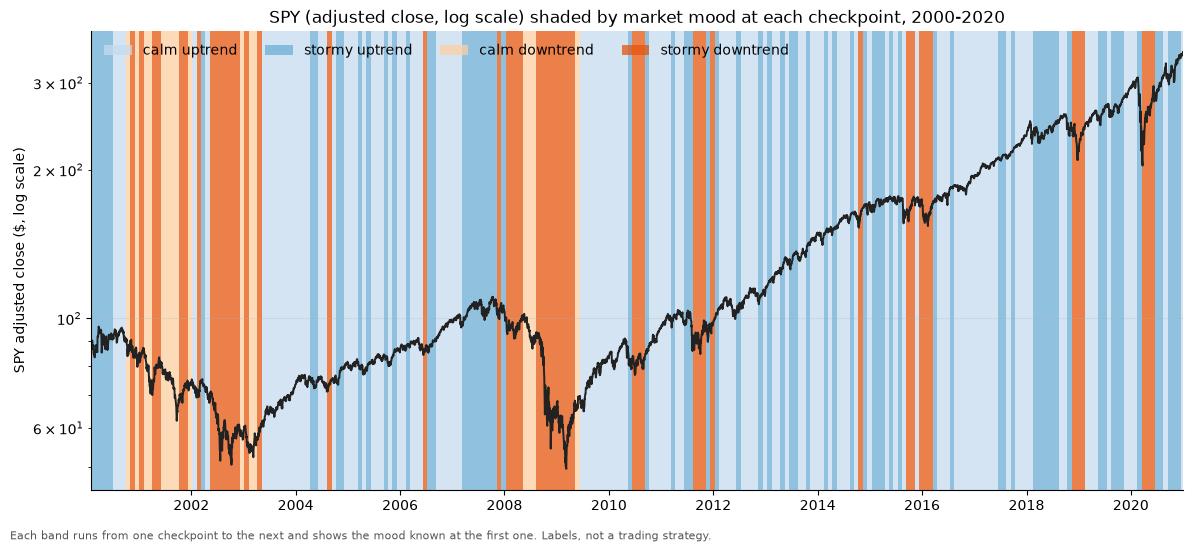

In [10]:
COL = {"calm uptrend": "#c6dbef", "stormy uptrend": "#6baed6", "calm downtrend": "#fdd0a2", "stormy downtrend": "#e6550d"}
fig, ax = plt.subplots(figsize=(12, 5.5))
ends = list(obs.pos.iloc[1:]) + [n - 1]
for (_, r), e in zip(obs.iterrows(), ends):
    ax.axvspan(P.index[int(r.pos)], P.index[int(e)], color=COL[r.mood], alpha=0.75, lw=0)
ax.plot(P.index, spy, color="#222222", lw=1.4)
ax.set_yscale("log")
ax.set_xlim(P.index[int(obs.pos.iloc[0])], P.index[-1])
ax.set_title("SPY (adjusted close, log scale) shaded by market mood at each checkpoint, 2000-2020")
ax.set_ylabel("SPY adjusted close ($, log scale)")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.grid(axis="y", alpha=0.25)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=COL[m], label=m, alpha=0.75) for m in MOODS] , ncol=4, loc="upper left", frameon=False)
fig.text(0.01, 0.01, "Each band runs from one checkpoint to the next and shows the mood known at the first one. Labels, not a trading strategy.", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(R / "06_spy_with_moods.png", dpi=130)
plt.show()

## 10. Summary of what is judged
Printed again for the write-up: D1, D2, D3 numbers. **This measures labels, not a trading strategy, and no trading costs are applied.**

In [11]:
print("D1 mood stays the same: %.1f%% (needs >= 60%%), chance %.1f%%" % (stk.stayed_same_pct.iloc[0], stk.chance_pct.iloc[0]))
print("D2 defensive excess: stormy (both) %.3f%% (needs > 0), calm uptrend %.3f%% (needs < 0)" % (
    d.loc[d.storm == "stormy", "def_excess"].mean() * 100, d.loc[d.mood == "calm uptrend", "def_excess"].mean() * 100))
print("D3 SPY next month: downtrend %.3f%% vs uptrend %.3f%% (needs downtrend lower)" % (d.loc[dn, "spy_ret"].mean() * 100, d.loc[up, "spy_ret"].mean() * 100))

D1 mood stays the same: 55.2% (needs >= 60%), chance 32.7%
D2 defensive excess: stormy (both) -0.136% (needs > 0), calm uptrend -0.025% (needs < 0)
D3 SPY next month: downtrend 0.344% vs uptrend 0.791% (needs downtrend lower)
